In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [3]:
# Load previous output from Step 4A
df = pd.read_csv("phase4A_ground_truth_labeled.csv")

# Filter out unknowns
df_filtered = df[df["ground_truth"].isin(["Abandoned", "Active"])].copy()

# Convert ground truth to binary: Abandoned = 1, Active = 0
df_filtered["ground_truth_numeric"] = df_filtered["ground_truth"].apply(lambda x: 1 if x == "Abandoned" else 0)


In [5]:
# Compute Pearson correlation
correlation, p_value = pearsonr(df_filtered["ARS"], df_filtered["ground_truth_numeric"])
print(f"📈 Pearson Correlation between ARS and Abandonment: {correlation:.2f} (p-value: {p_value:.4f})")

📈 Pearson Correlation between ARS and Abandonment: 0.83 (p-value: 0.0000)


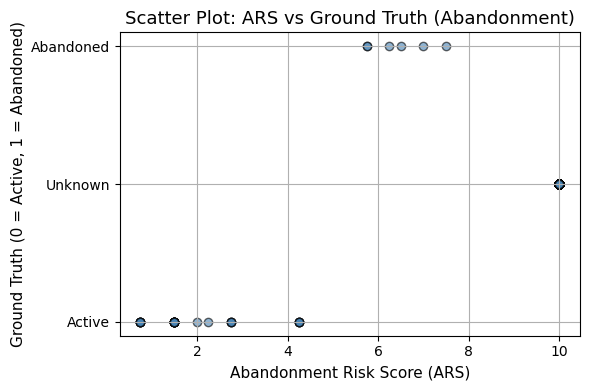

In [17]:
plt.figure(figsize=(6, 4))
plt.scatter(df["ARS"], df["ground_truth"], alpha=0.6, color="steelblue", edgecolors="black")

# Add titles and labels
plt.title("Scatter Plot: ARS vs Ground Truth (Abandonment)", fontsize=13)
plt.xlabel("Abandonment Risk Score (ARS)", fontsize=11)
plt.ylabel("Ground Truth (0 = Active, 1 = Abandoned)", fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()